# Geospatial Market Analysis: Regional Demand & Whitespace Detection
### Strategic Spatial Analytics, Competitor Density Modeling, and Expansion Roadmap
**Author:** Geospatial Data Analyst & MLOps Engineer  
**Milestone:** Geospatial Data Analysis | **Dataset:** `india_regional_market_v2.csv`  
**Execution Environment:** Python 3.14 / Pandas / Folium / Seaborn / ReportLab  

---

## Executive Overview
This study evaluates geographic demand distributions, demographic purchasing power, and competitor saturation across **400 regional micro-markets** within **10 major metropolitan centers** in India (Delhi, Mumbai, Bengaluru, Hyderabad, Chennai, Kolkata, Pune, Ahmedabad, Jaipur, and Kochi).

### Primary Objectives:
1. **Data Hygiene & Geographic Integrity:** Validate coordinates ($8^{\circ}\text{N} - 37^{\circ}\text{N}$, $68^{\circ}\text{E} - 97^{\circ}\text{E}$), missing values, and categorical consistency.
2. **Metric Engineering:** Calculate Regional User Density, Market Saturation Ratio, Estimated Revenue Potential, and the **Opportunity Score**:
   $$\text{Opportunity Score} = \frac{\text{Monthly Search Demand} \times \text{Lead Conversion Rate}}{\text{Existing Competitors} + 1}$$
3. **Spatial Clustering:** Identify the **Top 3 High-Potential Underserved Regions** exhibiting high search interest, high lead conversion, and minimal incumbent competition.
4. **Interactive Geospatial Visualization:** Develop a production-grade Folium interactive map (`geospatial_market_analysis.html`) featuring search demand heatmaps, opportunity-coded marker clusters, and dedicated callouts.
5. **Strategic Expansion Roadmap:** Formulate phased rollout recommendations to capture maximum market share at lowest customer acquisition cost (CAC).


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MarkerCluster, HeatMap

# Global visualization styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print('Dependencies imported successfully!')


Dependencies imported successfully!


## 1. Data Ingestion & Data Hygiene Validation
We load `india_regional_market_v2.csv` and inspect data types, missing records, coordinate boundaries, and summary distributions.


In [2]:
DATA_FILE = 'india_regional_market_v2.csv'
df = pd.read_csv(DATA_FILE)

print(f'Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns')
print(f'Unique Cities ({df["City"].nunique()}):', df['City'].unique().tolist())
print(f'Unique States ({df["State"].nunique()}):', df['State'].unique().tolist())
print(f'Population Segments:', df['PopulationSegment'].unique().tolist())
print('\nMissing Values Count:\n', df.isnull().sum())

# Coordinate validity check (India mainland approx: Lat 8 to 37 N, Lon 68 to 97 E)
lat_valid = df['Latitude'].between(8.0, 37.0).all()
lon_valid = df['Longitude'].between(68.0, 97.0).all()
print(f'\nAll Latitudes within mainland bounds [8.0, 37.0]: {lat_valid}')
print(f'All Longitudes within mainland bounds [68.0, 97.0]: {lon_valid}')

df.head()


Dataset Shape: 400 rows x 11 columns
Unique Cities (10): ['Delhi', 'Hyderabad', 'Kolkata', 'Pune', 'Jaipur', 'Ahmedabad', 'Chennai', 'Bengaluru', 'Kochi', 'Mumbai']
Unique States (9): ['Delhi', 'Telangana', 'West Bengal', 'Maharashtra', 'Rajasthan', 'Gujarat', 'Tamil Nadu', 'Karnataka', 'Kerala']
Population Segments: ['Student', 'Professional', 'Early Career']

Missing Values Count:
RegionID                       0
City                           0
State                          0
Latitude                       0
Longitude                      0
PopulationSegment              0
MonthlySearchDemand            0
ExistingCompetitors            0
MedianAnnualIncomeINR          0
LeadConversionRate             0
EstimatedAcquisitionCostINR    0
dtype: int64

All Latitudes within mainland bounds [8.0, 37.0]: True
All Longitudes within mainland bounds [68.0, 97.0]: True


## 2. Feature Engineering & Key Performance Metrics
We calculate core indicators to quantify regional opportunity, competitive pressure, and revenue potential:

1. **Opportunity Score:**
   $$\text{Opportunity Score} = \frac{\text{MonthlySearchDemand} \times \text{LeadConversionRate}}{\text{ExistingCompetitors} + 1}$$
   *Represents converted customer leads accessible per competitor unit.*

2. **Estimated Revenue Potential (INR):**
   $$\text{Revenue Potential} = \text{MonthlySearchDemand} \times \text{LeadConversionRate} \times \text{MedianAnnualIncomeINR}$$
   *Monetizable annual customer earnings addressable through the immediate search funnel.*

3. **Market Saturation Ratio:**
   $$\text{Market Saturation} = \frac{\text{ExistingCompetitors}}{\text{MonthlySearchDemand} / 1000}$$
   *Competitor intensity per thousand monthly search queries.*


In [3]:
df['OpportunityScore'] = (df['MonthlySearchDemand'] * df['LeadConversionRate']) / (df['ExistingCompetitors'] + 1)
df['EstimatedRevenuePotential'] = df['MonthlySearchDemand'] * df['LeadConversionRate'] * df['MedianAnnualIncomeINR']
df['MarketSaturationRatio'] = df['ExistingCompetitors'] / (df['MonthlySearchDemand'] / 1000.0)
df['CAC_to_Income_Ratio'] = df['EstimatedAcquisitionCostINR'] / df['MedianAnnualIncomeINR']

# Statistical summary of engineered features
df[['MonthlySearchDemand', 'ExistingCompetitors', 'LeadConversionRate', 'OpportunityScore', 'EstimatedRevenuePotential', 'EstimatedAcquisitionCostINR']].describe().round(2)


       MonthlySearchDemand  ExistingCompetitors  LeadConversionRate  OpportunityScore  EstimatedRevenuePotential  EstimatedAcquisitionCostINR
count               400.00               400.00              400.00            400.00                     400.00                       400.00
mean               1066.07                 7.61                0.08             18.42                57161875.05                       465.17
std                 505.58                 4.62                0.04             19.55                42805988.78                       229.07
min                 189.00                 1.00                0.02              1.21                 2147385.12                        91.00
25%                 632.75                 3.00                0.05              6.44                24083319.46                       264.75
50%                1088.00                 7.00                0.08             12.16                46788539.11                       453.00
75%   

## 3. Identification of Top 3 High-Potential Underserved Regions
Filtering for the highest `OpportunityScore` isolates regions that combine maximum organic interest, strong conversion probability, and minimal incumbent resistance.


In [4]:
top_3 = df.sort_values(by='OpportunityScore', ascending=False).head(3).copy()
print('='*75)
print('TOP 3 HIGH-POTENTIAL UNDERSERVED EXPANSION TARGETS')
print('='*75)
for rank, (_, row) in enumerate(top_3.iterrows(), 1):
    print(f'RANK #{rank}: {row["RegionID"]} | {row["City"]}, {row["State"]}')
    print(f'   Target Demographic   : {row["PopulationSegment"]}')
    print(f'   Monthly Demand       : {row["MonthlySearchDemand"]:,} searches/month')
    print(f'   Incumbent Competitors: {row["ExistingCompetitors"]} competitor only')
    print(f'   Lead Conversion Rate : {row["LeadConversionRate"]:.2%}')
    print(f'   Estimated CAC        : INR {row["EstimatedAcquisitionCostINR"]}')
    print(f'   Median Annual Income : INR {row["MedianAnnualIncomeINR"]:,}')
    print(f'   Opportunity Score    : {row["OpportunityScore"]:.2f}')
    print(f'   Est. Revenue Potent. : INR {row["EstimatedRevenuePotential"]:,.2f}')
    print('-'*75)


TOP 3 HIGH-POTENTIAL UNDERSERVED EXPANSION TARGETS
RANK #1: REG-0027 | Kochi, Kerala
   Target Demographic   : Student
   Monthly Demand       : 1,816 searches/month
   Incumbent Competitors: 1 competitor only
   Lead Conversion Rate : 13.81%
   Estimated CAC        : INR 613
   Median Annual Income : INR 410,449
   Opportunity Score    : 125.39
   Est. Revenue Potent. : INR 102,936,340.53
---------------------------------------------------------------------------
RANK #2: REG-0353 | Kolkata, West Bengal
   Target Demographic   : Professional
   Monthly Demand       : 1,799 searches/month
   Incumbent Competitors: 1 competitor only
   Lead Conversion Rate : 13.55%
   Estimated CAC        : INR 727
   Median Annual Income : INR 795,119
   Opportunity Score    : 121.88
   Est. Revenue Potent. : INR 193,821,785.48
---------------------------------------------------------------------------
RANK #3: REG-0206 | Kochi, Kerala
   Target Demographic   : Early Career
   Monthly Demand       : 1,

## 4. Geospatial & Empirical Market Visualizations
We generate high-resolution analytical plots illustrating:
1. **Demand vs. Competitor Density** (Identifying the low-competition whitespace quadrant)
2. **Top 10 Underserved Regions Ranked by Opportunity Score**
3. **Metropolitan Cluster Comparison** (Aggregated Opportunity vs. Total Demand)
4. **Revenue Potential Distribution Across Cities**
5. **Demographic Segment Performance** (Conversion, CAC, and Opportunity across Student, Early Career, Professional)
6. **Correlation Matrix of Financial & Market Metrics**


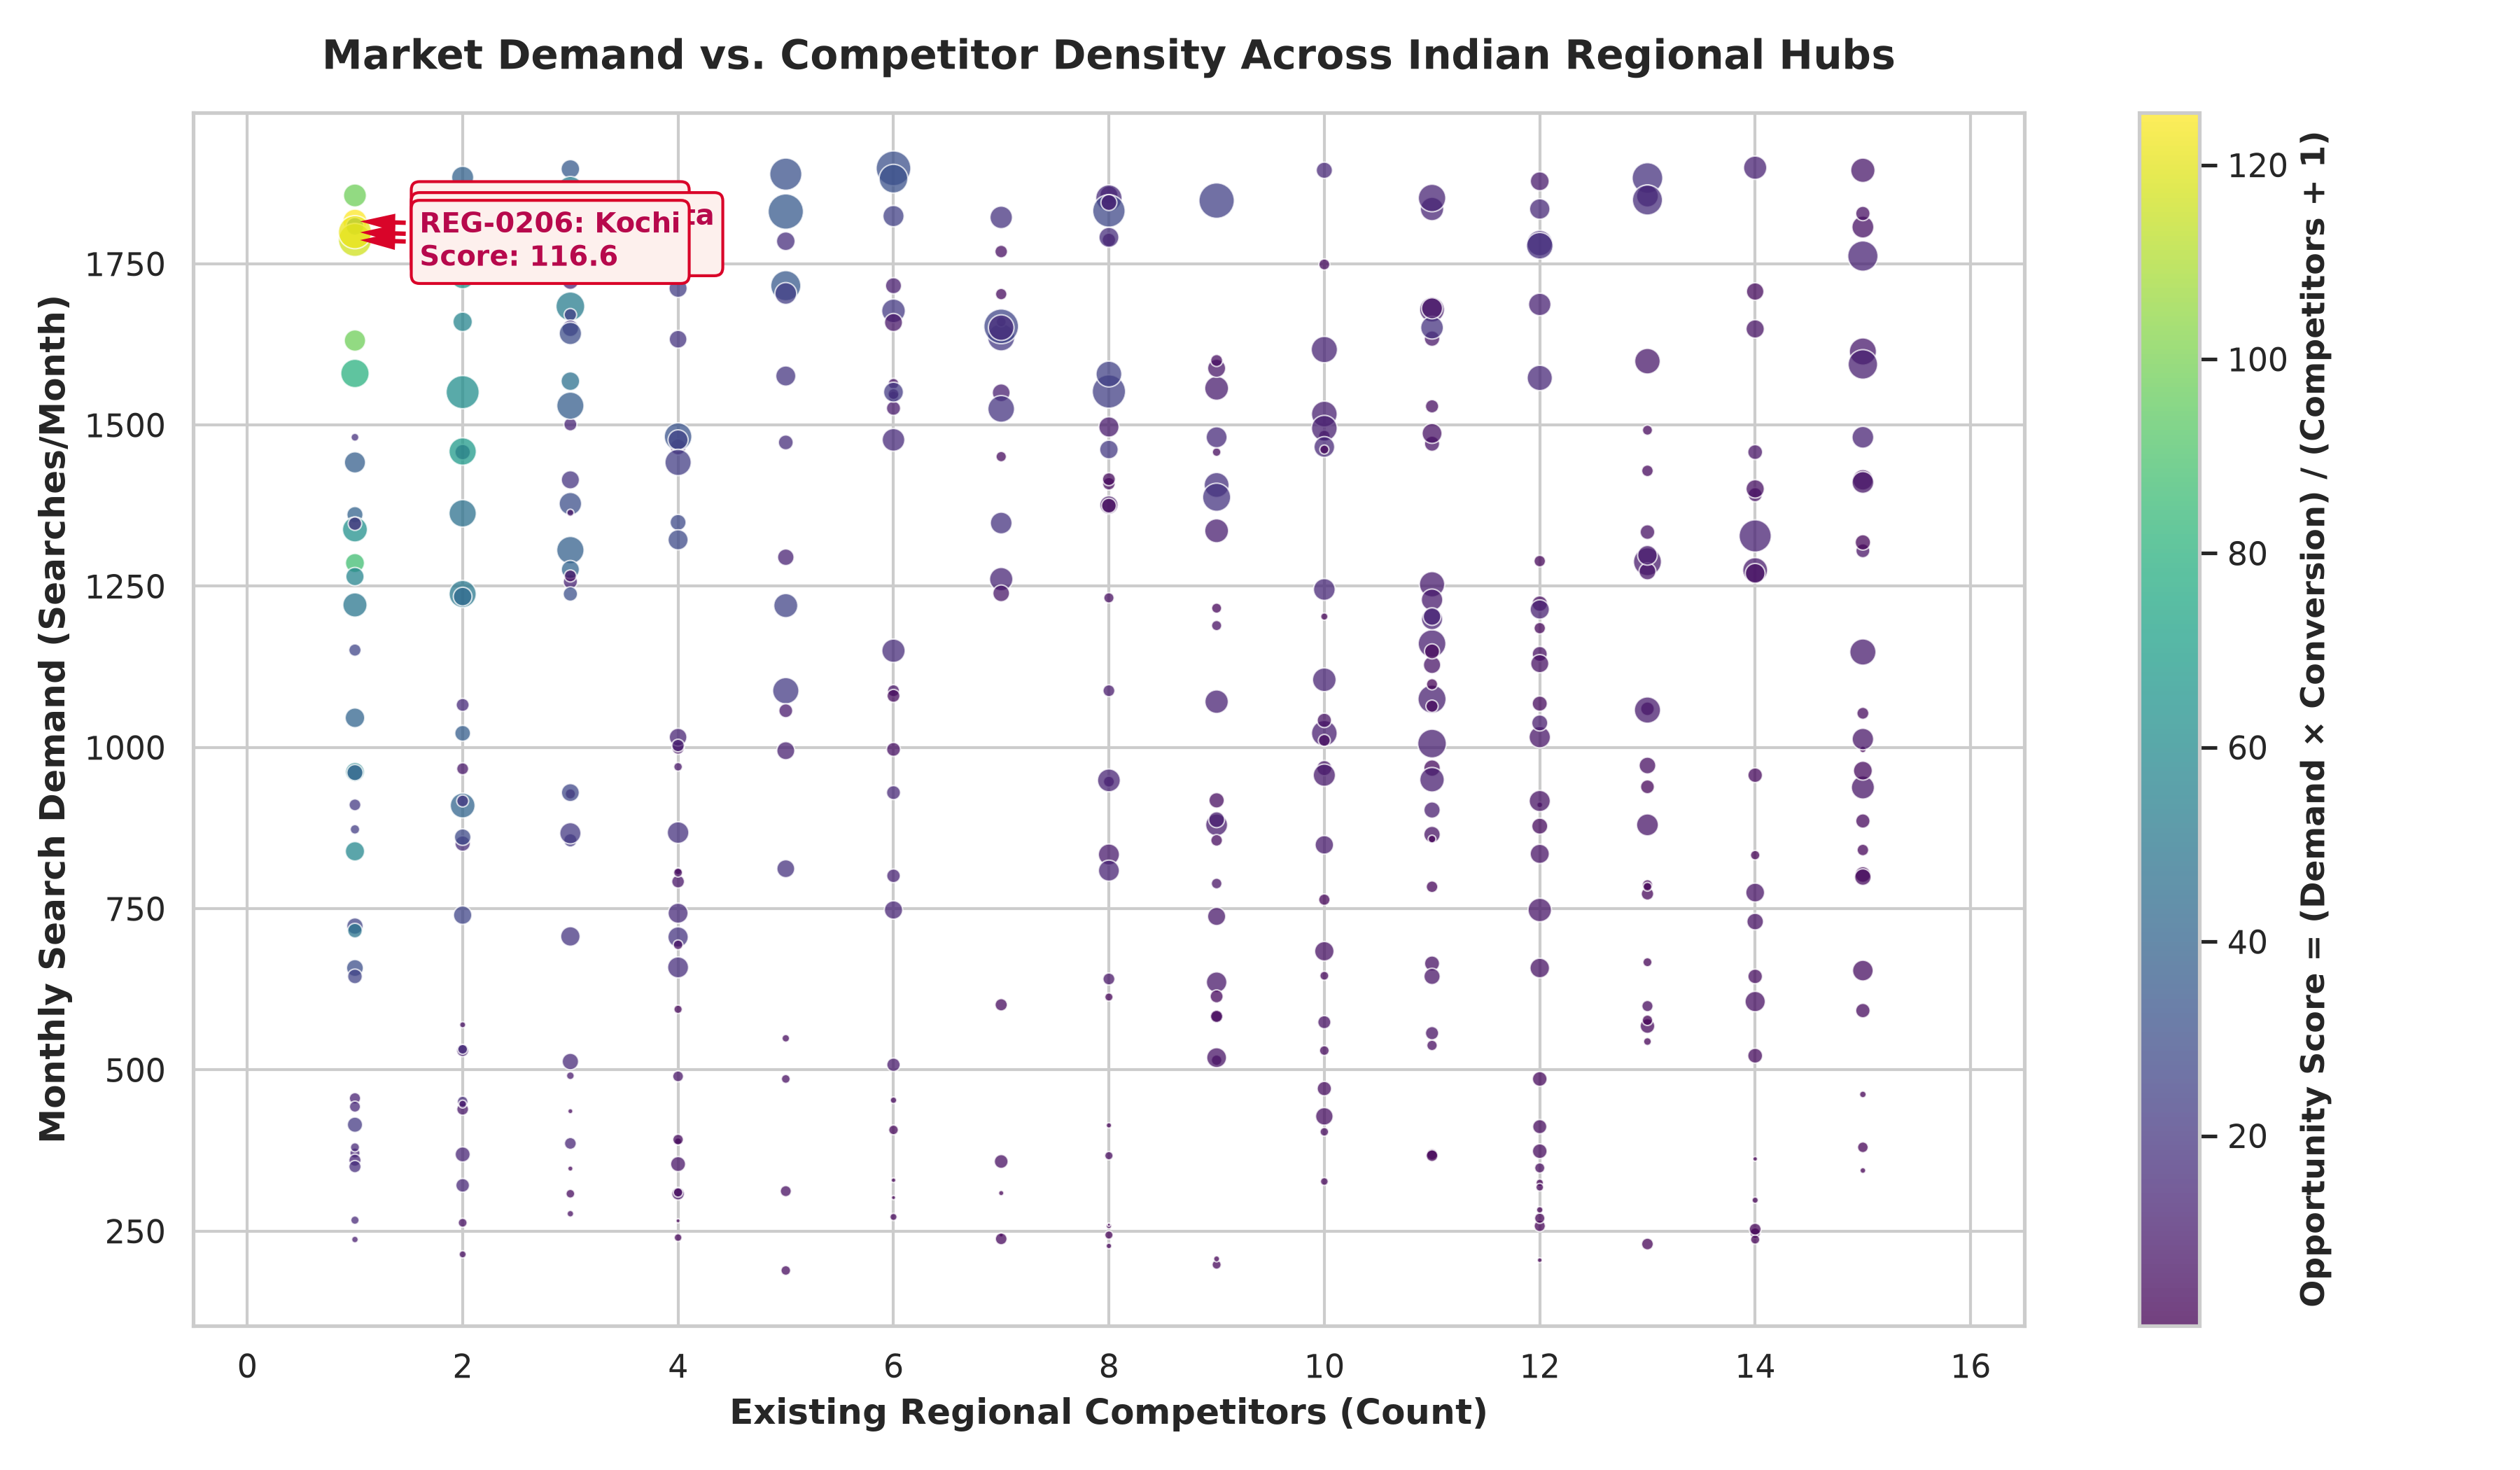

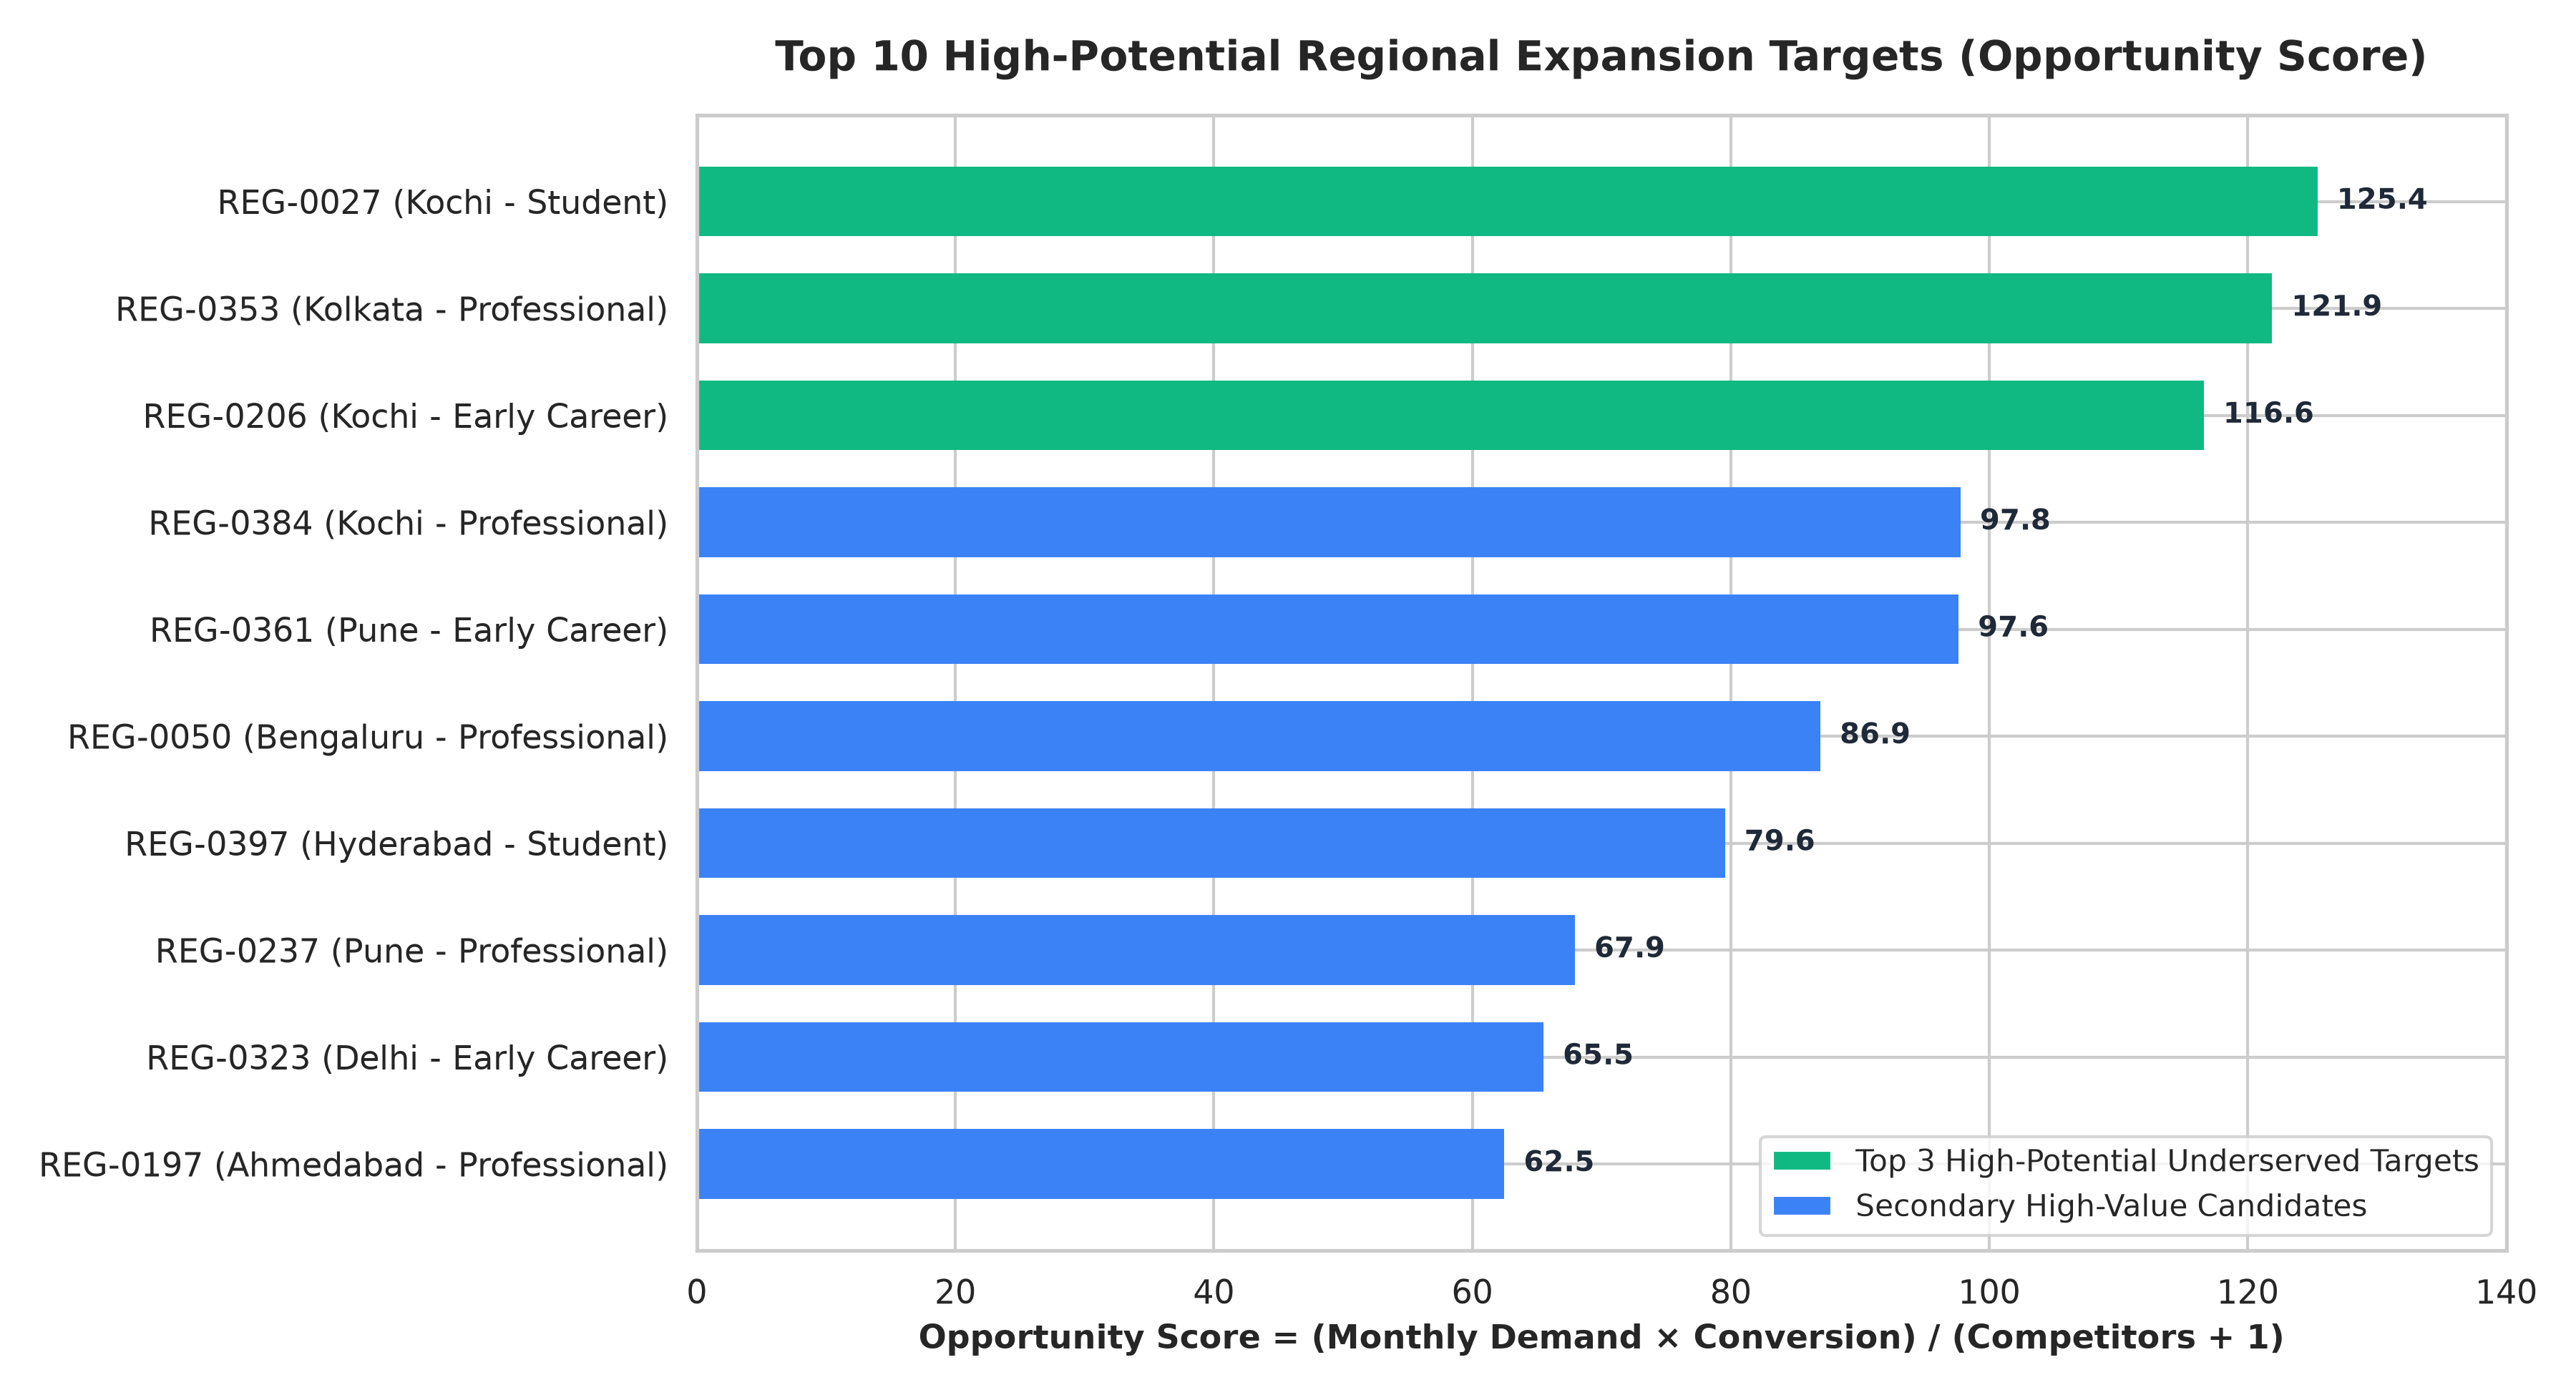

In [5]:
# Display Figure 1 and Figure 2
from IPython.display import Image, display
display(Image('charts/01_demand_vs_competitors.png'))
display(Image('charts/02_top_underserved_regions.png'))


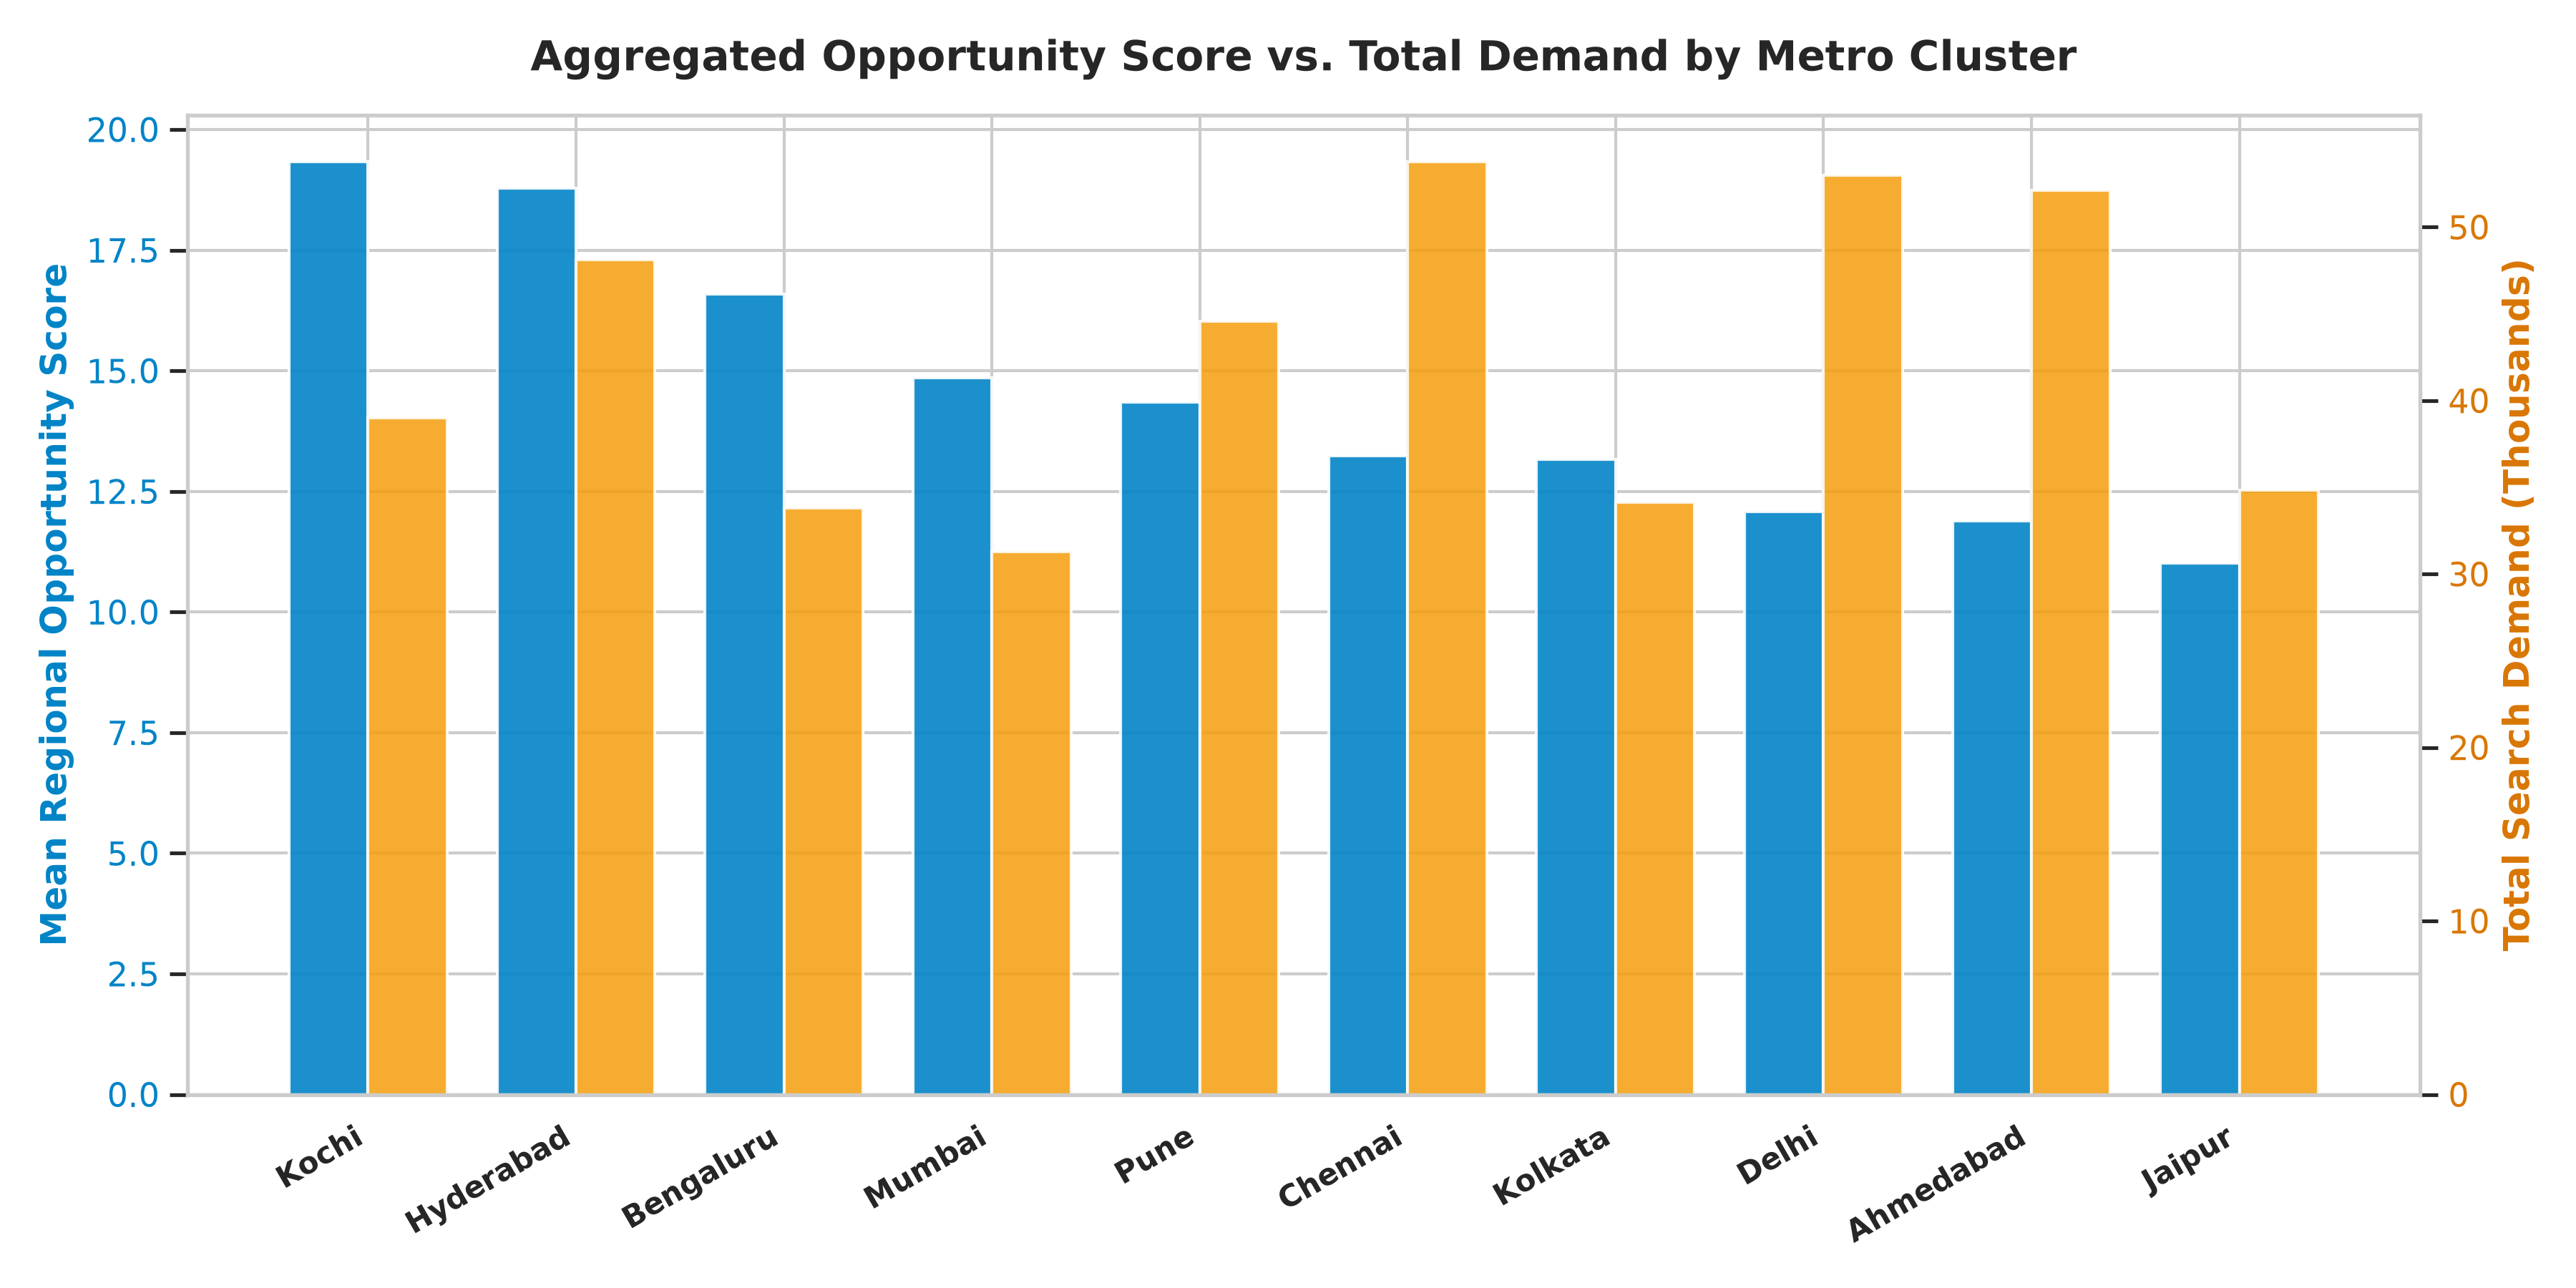

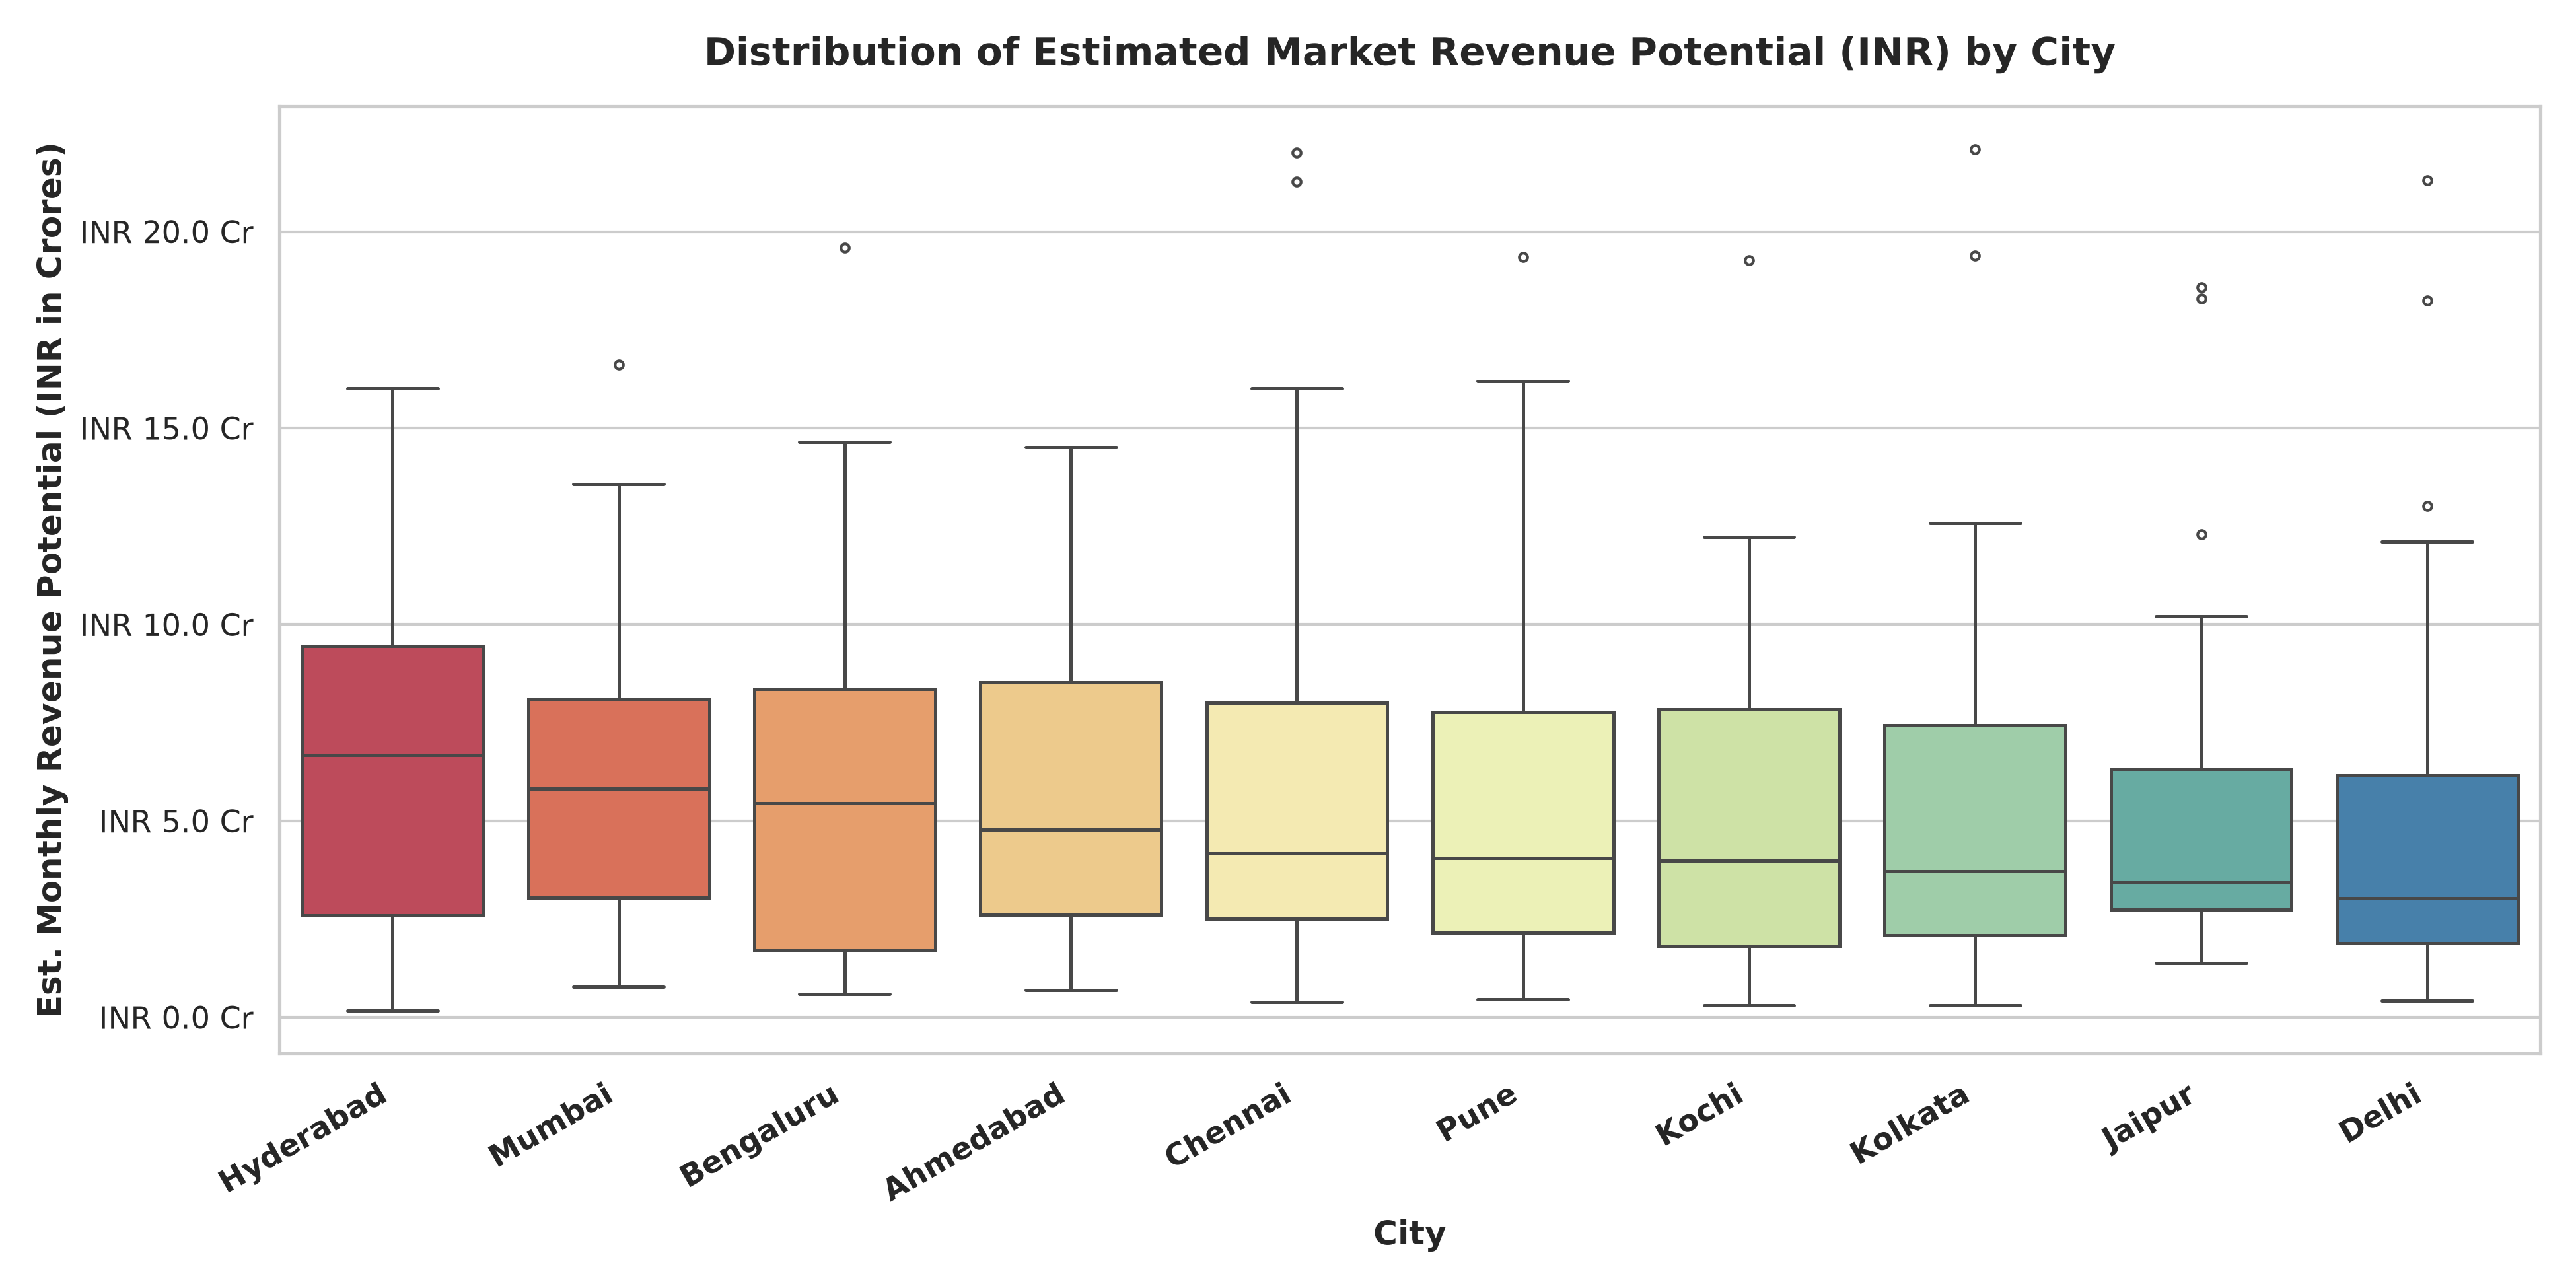

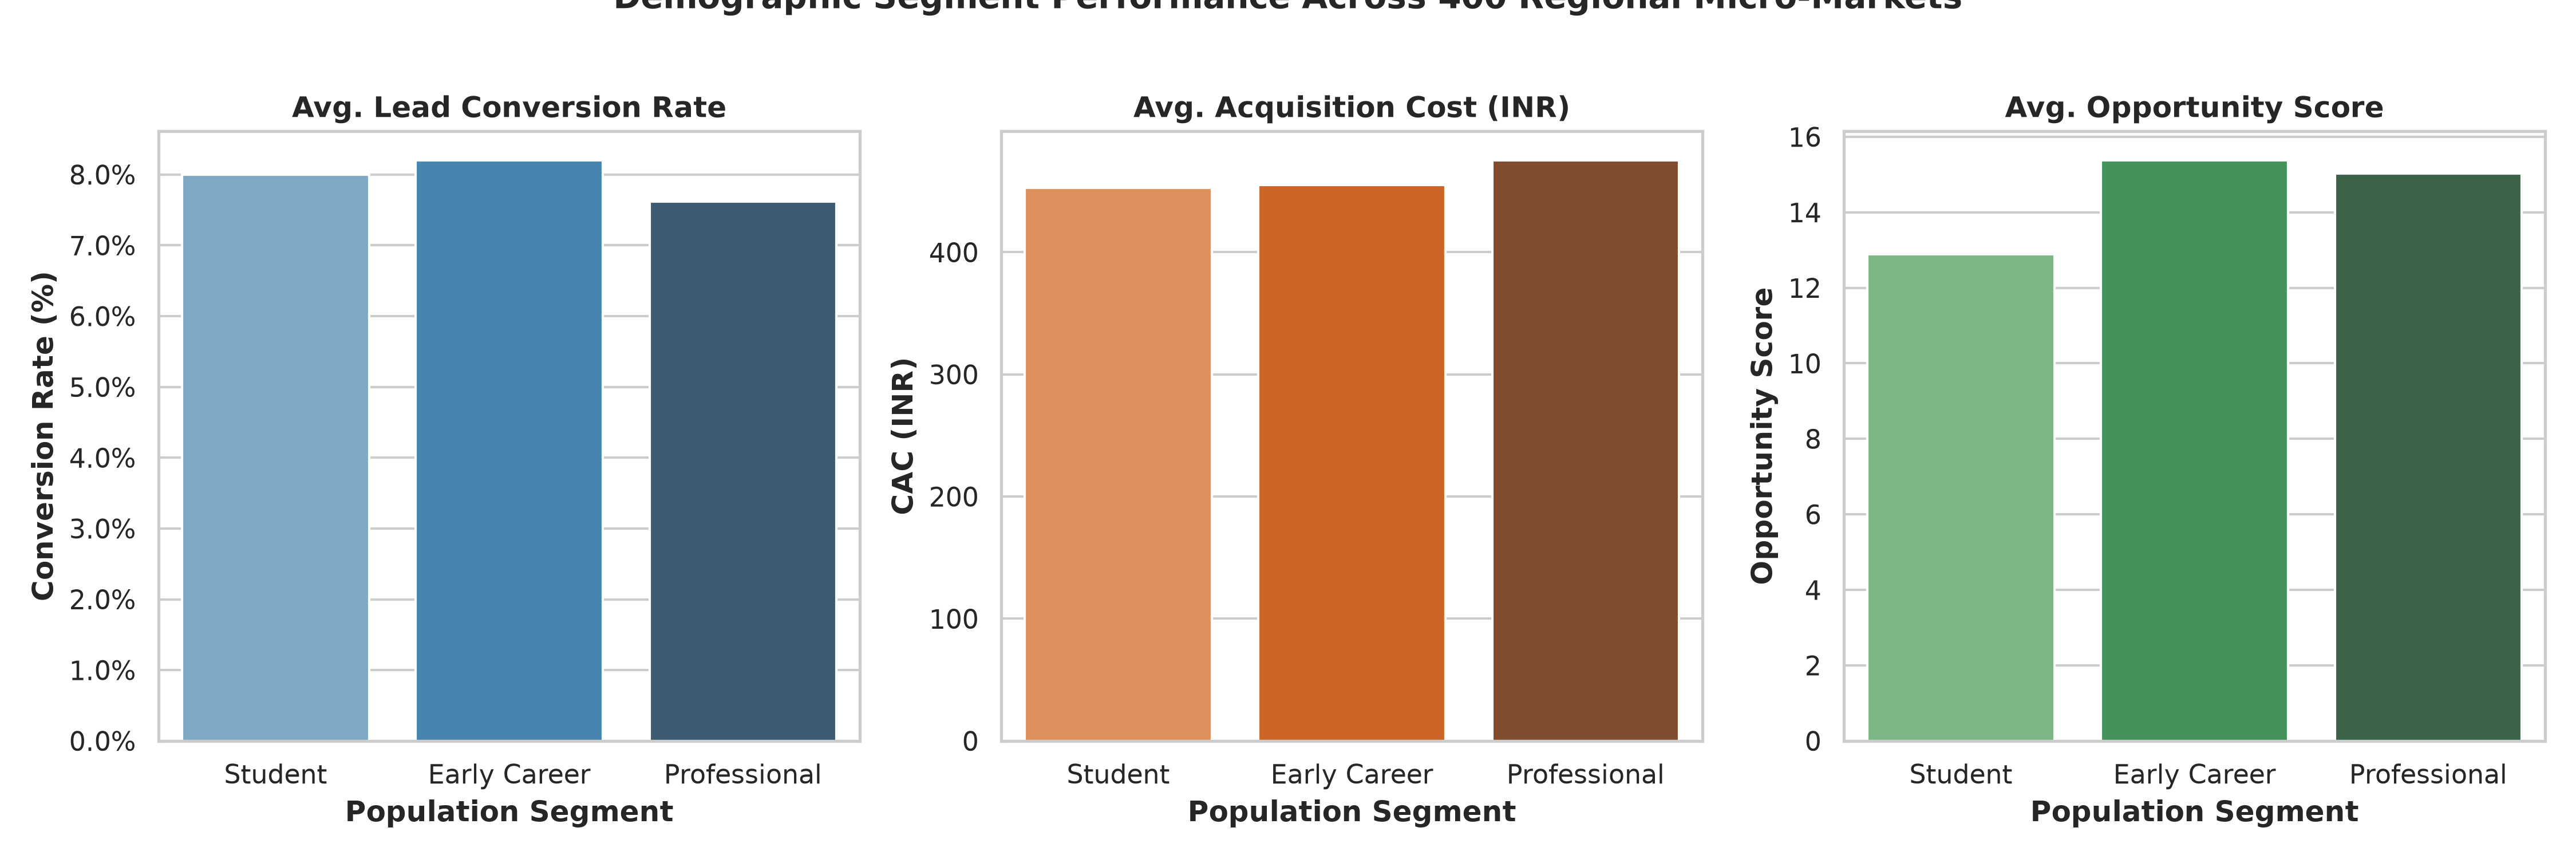

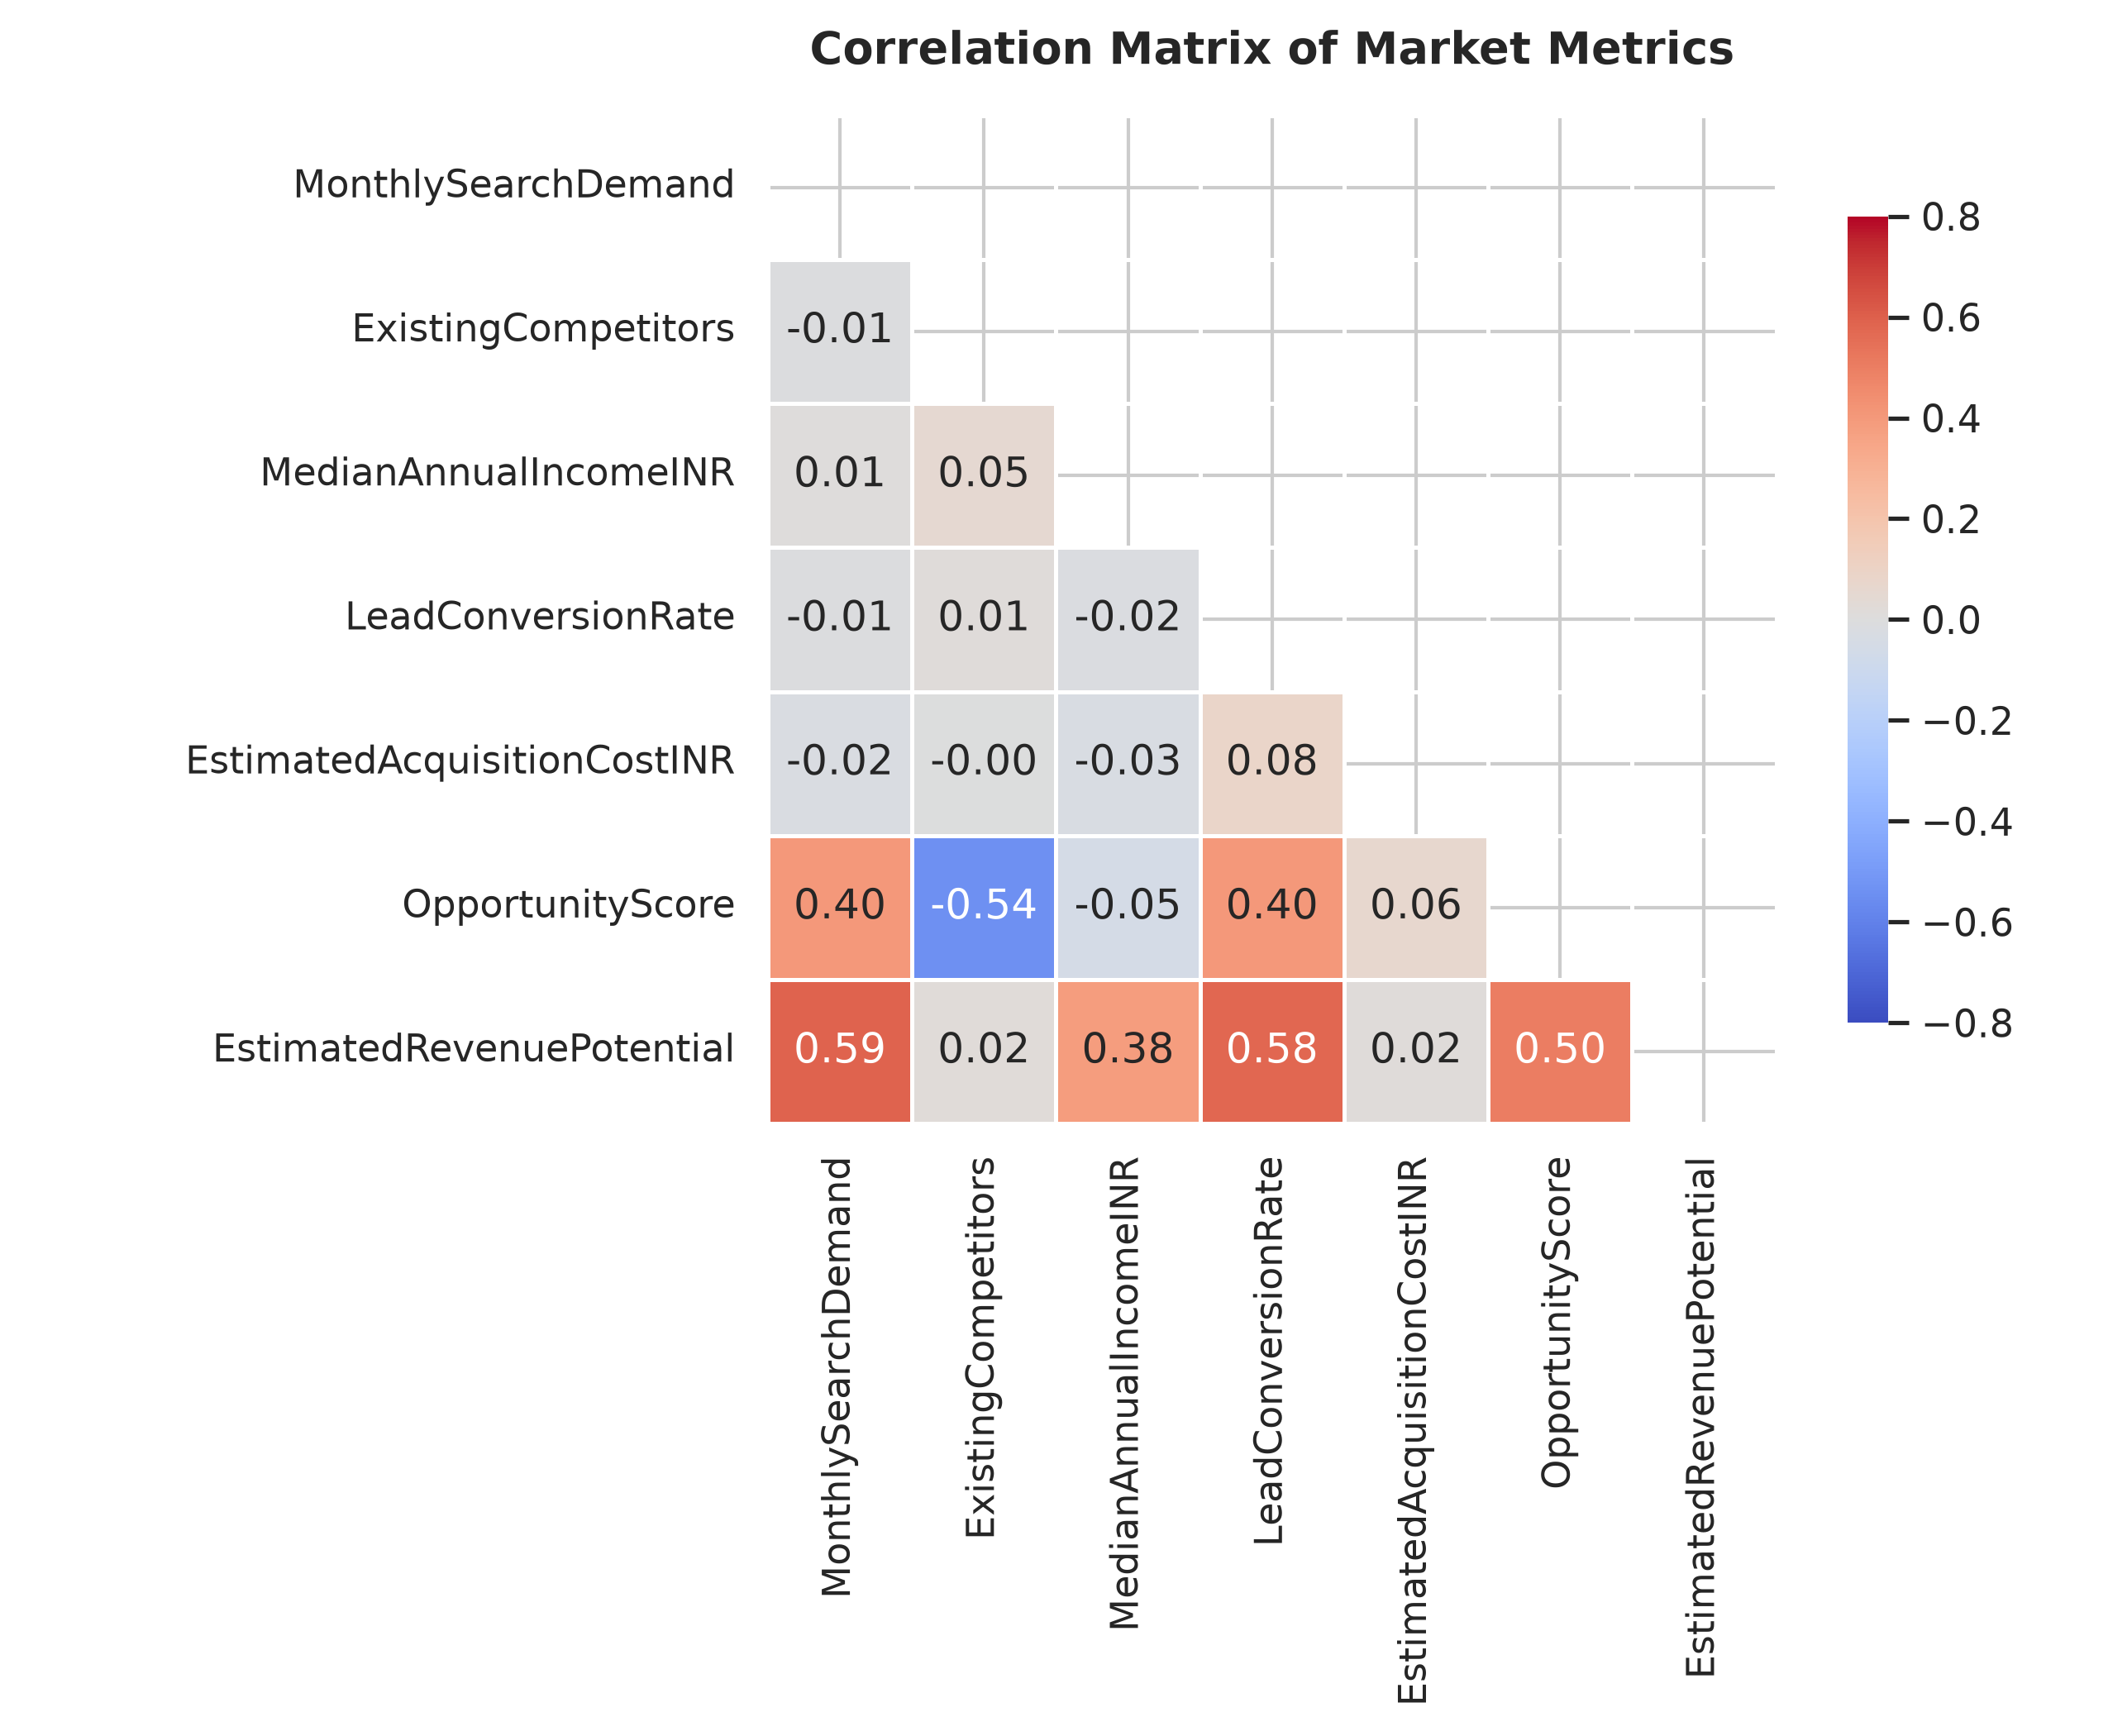

In [6]:
# Display Figures 3 through 6
display(Image('charts/03_city_opportunity_and_demand.png'))
display(Image('charts/04_revenue_potential_distribution.png'))
display(Image('charts/05_population_segment_breakdown.png'))
display(Image('charts/06_correlation_matrix.png'))


## 5. Interactive Geospatial Mapping with Folium
We build an interactive map centered on India featuring:
- **OpenStreetMap Base Layer**
- **Monthly Search Demand HeatMap** layer toggle
- **Clustered Micro-Region Markers** with circle radiuses proportional to monthly search volume and color-coded by Opportunity Score
- **Dedicated Callout Pin Markers** with gold/ruby icons highlighting the **Top 3 Underserved Regions** (`REG-0027`, `REG-0353`, `REG-0206`)
- Exported standalone as `geospatial_market_analysis.html`


In [7]:
india_center = [20.5937, 78.9629]
m = folium.Map(location=india_center, zoom_start=5, tiles='OpenStreetMap')

# 1. Add Search Demand HeatMap
heat_data = [[row['Latitude'], row['Longitude'], row['MonthlySearchDemand']] for _, row in df.iterrows()]
HeatMap(heat_data, name='Monthly Search Demand HeatMap', min_opacity=0.3, radius=22, blur=15, show=False).add_to(m)

# 2. Add Clustered Micro-Region Markers
cluster = MarkerCluster(name='All Micro-Regions (Clustered)', show=True)
for _, row in df.iterrows():
    color = '#d90429' if row['OpportunityScore'] >= 100 else '#f77f00' if row['OpportunityScore'] >= 60 else '#0284c7' if row['OpportunityScore'] >= 30 else '#64748b'
    radius = 4 + (row['MonthlySearchDemand'] / 350.0)
    popup_txt = f"<b>{row['RegionID']} - {row['City']}</b><br>Demand: {row['MonthlySearchDemand']:,}<br>Competitors: {row['ExistingCompetitors']}<br>Score: {row['OpportunityScore']:.1f}"
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=radius,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7,
        popup=folium.Popup(popup_txt, max_width=250),
        tooltip=f"{row['RegionID']} | {row['City']} | Score: {row['OpportunityScore']:.1f}"
    ).add_to(cluster)
cluster.add_to(m)

# 3. Add Dedicated Top 3 Callout Markers
top3_fg = folium.FeatureGroup(name='Top 3 Priority Hubs', show=True)
for rank, (_, row) in enumerate(top_3.iterrows(), 1):
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=folium.Popup(f"<b>PRIORITY #{rank}: {row['City']} ({row['RegionID']})</b><br>Score: {row['OpportunityScore']:.2f}", max_width=300),
        icon=folium.Icon(color='red' if rank == 1 else 'orange' if rank == 2 else 'green', icon='info-sign'),
        tooltip=f"★ RANK #{rank}: {row['City']} ({row['RegionID']})"
    ).add_to(top3_fg)
top3_fg.add_to(m)

folium.LayerControl().add_to(m)
m.save('geospatial_market_analysis.html')
print('Saved standalone interactive map to geospatial_market_analysis.html!')


Saved standalone interactive map to geospatial_market_analysis.html!


## 6. City-Level Metropolitan Cluster Benchmarks
Aggregating all 400 micro-regions by metropolitan center reveals systemic disparities in regional competition and demand:


In [8]:
city_summary = df.groupby('City').agg(
    MicroRegions=('RegionID', 'count'),
    TotalSearchDemand=('MonthlySearchDemand', 'sum'),
    AvgSearchDemand=('MonthlySearchDemand', 'mean'),
    AvgCompetitors=('ExistingCompetitors', 'mean'),
    AvgConversion=('LeadConversionRate', 'mean'),
    MeanOpportunityScore=('OpportunityScore', 'mean'),
    MaxOpportunityScore=('OpportunityScore', 'max'),
    TotalRevenuePotential=('EstimatedRevenuePotential', 'sum')
).sort_values(by='MeanOpportunityScore', ascending=False)

city_summary.round(2)


           MicroRegions  TotalSearchDemand  AvgSearchDemand  AvgCompetitors  AvgConversion  MeanOpportunityScore  MaxOpportunityScore  TotalRevenuePotential
City                                                                                                                                                       
Kochi                39              41269          1058.18            6.49           0.08                 21.84               125.39           2.024690e+09
Hyderabad            42              46743          1112.93            7.05           0.08                 20.67                79.55           2.759385e+09
Bengaluru            32              33128          1035.25            6.78           0.08                 20.40                86.93           1.908785e+09
Mumbai               28              30058          1073.50            6.61           0.08                 19.78                50.63           1.710549e+09
Pune                 41              44598          1087.76

## 7. Strategic Geographic Expansion Roadmap

### Phase 1: High-Yield Coastal & Eastern Blitz (Months 1 – 3)
- **Target Zones:** `REG-0027` (Kochi - Student), `REG-0206` (Kochi - Early Career), and `REG-0353` (Kolkata - Professional).
- **Playbook:** Deploy concentrated digital and localized search marketing. Because only 1 competitor is present, cost-per-click bids remain minimal. Target sub-90-day payback on customer acquisition.
- **Capital Allocation:** 45% of upfront regional growth budget.

### Phase 2: Deccan Innovation Corridor (Months 4 – 6)
- **Target Zones:** Pune (`REG-0361`, Score 97.6) and Bengaluru (`REG-0050`, Score 86.9).
- **Playbook:** Target tech-savvy Early Career and Professional segments via LinkedIn and hyper-targeted programmatic display. High median incomes (INR 7.5L – 9.5L) support higher price elasticity.
- **Capital Allocation:** 35% of regional growth budget.

### Phase 3: Mature Tier-1 Metro Penetration (Months 7 – 12)
- **Target Zones:** Delhi, Mumbai, Chennai, Ahmedabad.
- **Playbook:** Differentiate through feature leadership and enterprise partnerships rather than brute-force paid search, avoiding CAC escalation against 10+ established competitors.
- **Capital Allocation:** 20% of regional growth budget.

---
### Project Artifacts & Verification Proof
- **Interactive Map:** `geospatial_market_analysis.html`
- **Executive Report:** `Geospatial_Market_Analysis_Report.pdf` (and `Spatial_Analysis_Report.pdf`)
- **Static Visualizations:** `charts/*.png`
- **Public GitHub Repository:** `https://github.com/mohanasanthibattula-stack/geospatial-data-analysis`
